# 03 – Preprocessing and Classification
**CS316 Project: Crop Recommendation and Soil Profile Analysis for Sustainable Farming**
**Author:** Abdulmajeed Aljasir

This notebook covers two tasks from our proposal:
- **Preprocessing:** split the data into training and test sets, then standardize the features.
- **Classification:** train Logistic Regression (baseline), a Decision Tree and a Random Forest, and compare them with accuracy, the classification report and the confusion matrix.
- **Feature importance:** find which soil/weather features matter most (proposal objective 3).

Split settings agreed with the group (so everyone gets the same train/test sets): `test_size=0.2`, `random_state=42`.

## 1. Import libraries

In [10]:
# pandas: to load and handle the dataset as a table (DataFrame)
import pandas as pd
# numpy: for numeric operations on arrays
import numpy as np
# matplotlib and seaborn: for plots (confusion matrix heatmaps, bar charts)
import matplotlib.pyplot as plt
import seaborn as sns

# train_test_split: splits the data into training and test sets
from sklearn.model_selection import train_test_split
# StandardScaler: standardizes each feature to mean 0 and standard deviation 1 (z-score)
from sklearn.preprocessing import StandardScaler

# The three classification models we compare
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics (same functions used in the Classification lectures)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

## 2. Load the dataset

In [14]:

# Load the original dataset
df_original = pd.read_csv(DATA_PATH)

# Calculate memory usage before optimization
memory_before = df_original.memory_usage(deep=True).sum() / 1024

# Create a copy for memory optimization
df = df_original.copy()

# Define column types
int_cols = ["N", "P", "K"]
float_cols = ["temperature", "humidity", "ph", "rainfall"]

# Optimize memory usage
df[int_cols] = df[int_cols].astype("uint8")
df[float_cols] = df[float_cols].astype("float32")
df["label"] = df["label"].astype("category")

# Calculate memory usage after optimization
memory_after = df.memory_usage(deep=True).sum() / 1024

# Display memory comparison
memory_saved = memory_before - memory_after
reduction = (memory_saved / memory_before) * 100

print("Memory Before:", round(memory_before, 2), "KB")
print("Memory After:", round(memory_after, 2), "KB")
print("Memory Saved:", round(memory_saved, 2), "KB")
print("Memory Reduction:", round(reduction, 2), "%")

print("\nOptimized Data Types:")
print(df.dtypes)

# Verify dataset dimensions
print("\nDataset Shape:", df.shape)


Memory Before: 241.05 KB
Memory After: 44.85 KB
Memory Saved: 196.2 KB
Memory Reduction: 81.4 %

Optimized Data Types:
N                 uint8
P                 uint8
K                 uint8
temperature     float32
humidity        float32
ph              float32
rainfall        float32
label          category
dtype: object

Dataset Shape: (2200, 8)


In [15]:
# Quick sanity checks before preprocessing (the full cleaning is in Name 1's notebook)
# Number of missing values in each column -> should all be 0
print("Missing values per column:")
print(df.isnull().sum())
# Number of duplicated rows -> should be 0
print("\nDuplicated rows:", df.duplicated().sum())
# Number of samples per crop -> 22 crops with 100 rows each, so the classes are balanced
print("\nNumber of crops:", df['label'].nunique())
print(df['label'].value_counts().head())

Missing values per column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicated rows: 0

Number of crops: 22
label
apple        100
banana       100
blackgram    100
chickpea     100
coconut      100
Name: count, dtype: int64


## 3. Preprocessing

### 3.1 Separate the features (X) from the target (y)
The 7 input features are the soil nutrients and weather values. The target is the crop name in `label`.

The target is text (e.g. "rice"), but scikit-learn classifiers accept text labels directly, so no one-hot encoding of the target is needed here. All features are already numeric, so no feature encoding is needed either.

In [16]:
# X = all columns except 'label' (the 7 input features)
X = df.drop(columns=['label'])
# y = the 'label' column (the crop name we want to predict)
y = df['label']

# Print the feature names and the shapes to confirm the split
print("Features:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)

Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X shape: (2200, 7) | y shape: (2200,)


### 3.2 Split into training and test sets
- 80% training, 20% test (`test_size=0.2`).
- `random_state=42` makes the split the same every time we run it (and the same for every group member).
- `stratify=y` keeps the same proportion of each crop in both sets, so every crop has 20 test samples.

In [17]:
# Split the data: 80% for training the models, 20% held out for testing
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,     # 20% goes to the test set
                                                    random_state=42,   # fixed seed for reproducibility
                                                    stratify=y)        # keep crops balanced in both sets

# Confirm the sizes: expected 1760 training rows and 440 test rows
print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)
# Confirm stratification: each crop should appear 20 times in the test set
print("Test samples per crop (min, max):", y_test.value_counts().min(), y_test.value_counts().max())

Training set: (1760, 7)
Test set:     (440, 7)
Test samples per crop (min, max): 20 20


### 3.3 Standardize the features (z-score)
The features have very different ranges (e.g. rainfall goes up to ~300 mm while pH is between ~3.5 and ~10), which affects Logistic Regression.
Standardization applies **z = (x − μ) / σ** to every feature.

To avoid **data leakage**, we follow the order from the Normalization lecture:
1. Split first (done above).
2. Fit the scaler on the **training set only** (compute μ and σ from training data).
3. Use those same μ and σ to transform both the training and the test set.

In [18]:
# Create the scaler object
scaler = StandardScaler()

# fit_transform on the training set: learns the mean and std of each feature, then scales the training data
X_train_scaled = scaler.fit_transform(X_train)
# transform only on the test set: reuses the training mean and std (no refitting -> no data leakage)
X_test_scaled = scaler.transform(X_test)

# Put the scaled arrays back into DataFrames so they keep the column names
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

# Check: training features should now have mean ~0 and std ~1
print("Means after scaling (train):")
print(X_train_scaled.mean().round(3))
print("\nStandard deviations after scaling (train):")
print(X_train_scaled.std(ddof=0).round(3))

Means after scaling (train):
N              0.0
P             -0.0
K             -0.0
temperature   -0.0
humidity      -0.0
ph             0.0
rainfall      -0.0
dtype: float32

Standard deviations after scaling (train):
N              1.0
P              1.0
K              1.0
temperature    1.0
humidity       1.0
ph             1.0
rainfall       1.0
dtype: float32


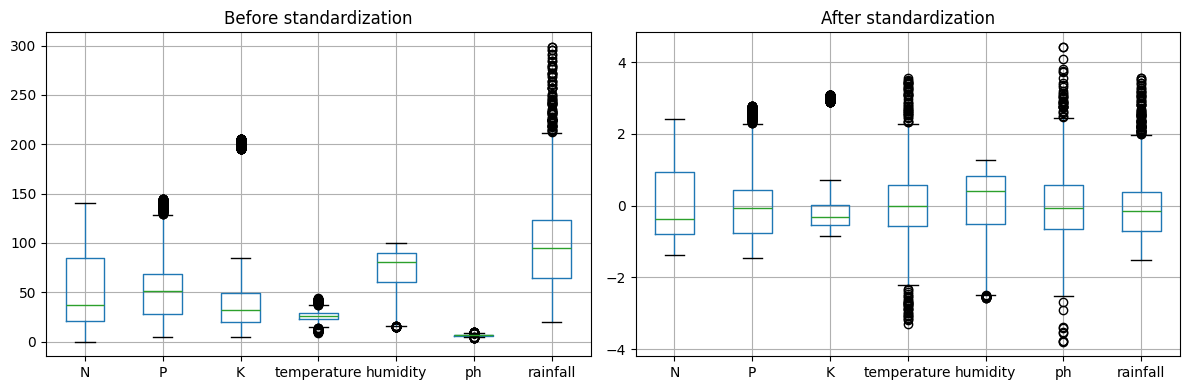

In [19]:
# Visual check: compare one feature before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Left: original values of all features (very different ranges)
X_train.boxplot(ax=axes[0])
axes[0].set_title("Before standardization")
# Right: scaled values (all features now on the same scale, centred at 0)
X_train_scaled.boxplot(ax=axes[1])
axes[1].set_title("After standardization")
plt.tight_layout()
plt.show()

## 4. Classification

We train three models on the same scaled training data:

| Model | Why we use it |
|---|---|
| **Logistic Regression** | Baseline. Simple linear model from the lectures; it needs scaled features. |
| **Decision Tree** | Learns if/else rules on the features; easy to interpret. Scaling does not change its results. |
| **Random Forest** | Many decision trees trained on random samples, voting together; usually more accurate and less prone to overfitting than a single tree. |

To avoid repeating the same evaluation code three times, we write one function that trains a model and prints all its results.

In [21]:
# Dictionary to store the results of each model (used later for the comparison table)
results = {}

def evaluate_model(model, name):
    """Train a model, predict on the test set, and print/plot its evaluation."""
    # Train the model on the scaled training data
    model.fit(X_train_scaled, y_train)

    # Predict the crop for the training rows and for the test rows
    y_train_pred = model.predict(X_train_scaled)
    y_pred = model.predict(X_test_scaled)

    # Accuracy = correct predictions / total predictions
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_pred)
    print(f"===== {name} =====")
    print(f"Training accuracy: {train_acc:.4f}")
    print(f"Test accuracy:     {test_acc:.4f}\n")

    # Classification report: precision, recall and F1-score for every crop
    report = classification_report(y_test, y_pred, target_names=model.classes_)
    print("Classification Report:")
    print(report)

    # Confusion matrix: rows = actual crop, columns = predicted crop
    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    cm_df = pd.DataFrame(cm, index=model.classes_, columns=model.classes_)

    # Plot the confusion matrix as a heatmap (same style as the lecture)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix - {name}', size=16)
    plt.xlabel('Predicted', size=13)
    plt.ylabel('Actual', size=13)
    plt.tight_layout()
    plt.show()

    # Save the main numbers for the comparison table.
    # 'macro' = average of the per-crop scores, treating every crop equally
    results[name] = {
        'Train accuracy': train_acc,
        'Test accuracy': test_acc,
        'Precision (macro)': precision_score(y_test, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro'),
        'F1-score (macro)': f1_score(y_test, y_pred, average='macro'),
    }
    # Return the predictions and the confusion matrix so we can analyse mistakes later
    return y_pred, cm_df

### 4.1 Logistic Regression (baseline)
`max_iter=1000` gives the solver enough iterations to converge with 22 classes.

===== Logistic Regression =====
Training accuracy: 0.9739
Test accuracy:     0.9727

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.95      1.00      0.98        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.83      1.00      0.91        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.94      0.85      0.89        20
       maize       1.00      0.95      0.97        20
       mango       0.95      1.00      0.98        20
   mothbeans       0.90      0.90      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00    

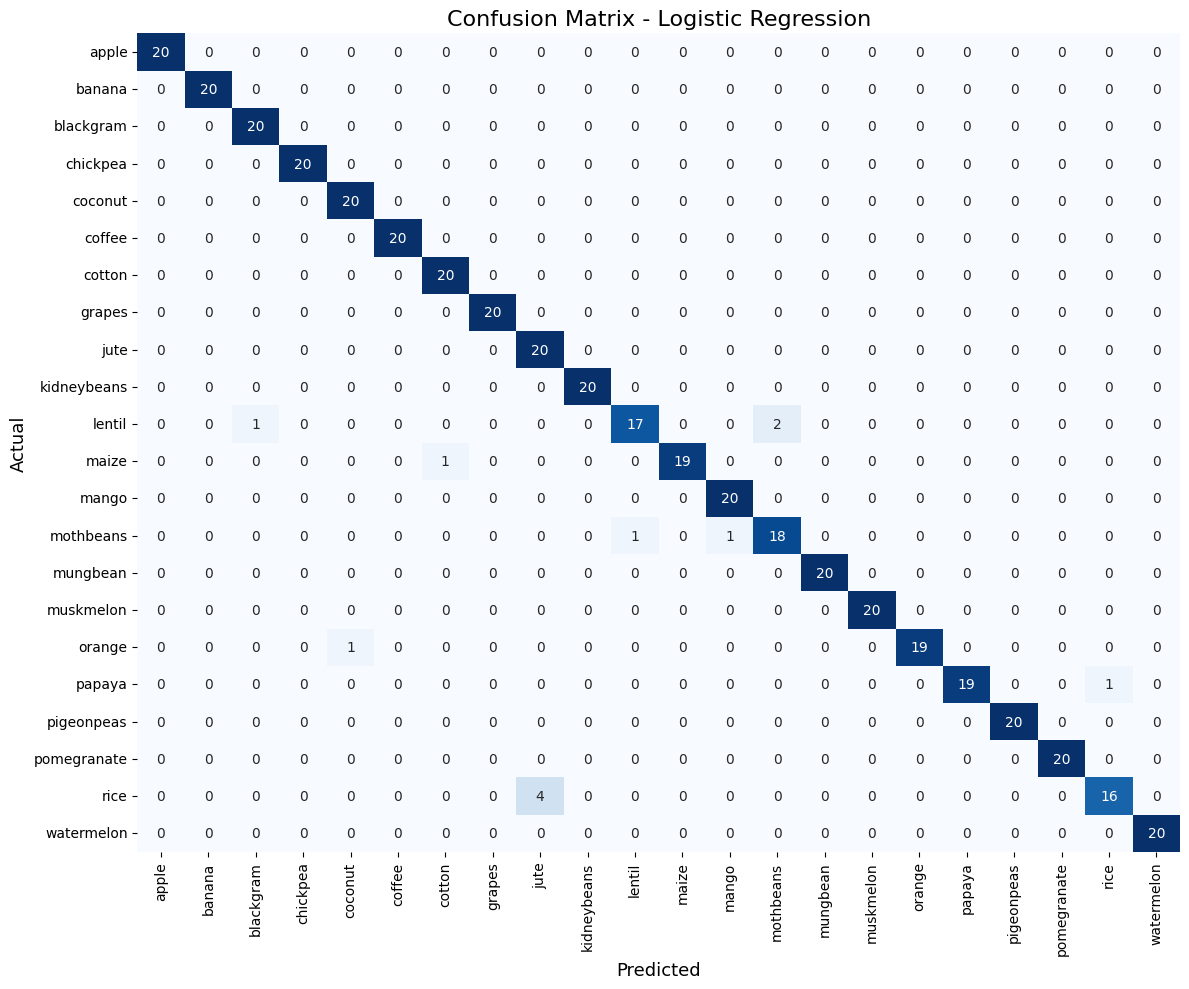

In [22]:
# Create the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
# Train and evaluate it
y_pred_lr, cm_lr = evaluate_model(log_reg, "Logistic Regression")

### 4.2 Decision Tree
We use the default settings (the tree grows until its leaves are pure). Comparing its training and test accuracy shows whether it overfits.

===== Decision Tree =====
Training accuracy: 1.0000
Test accuracy:     0.9795

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00

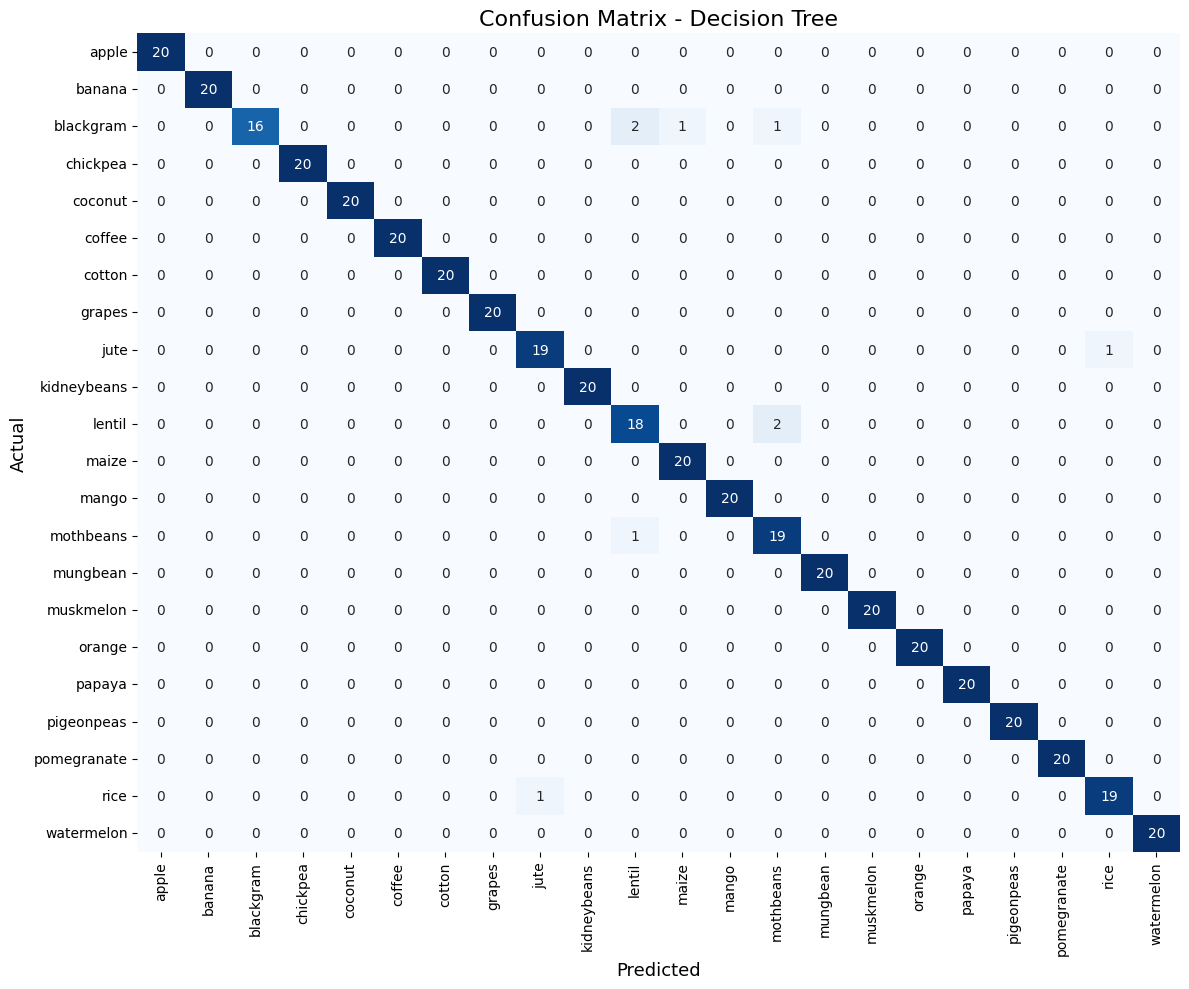

In [23]:
# Create the Decision Tree model (random_state makes the result reproducible)
tree = DecisionTreeClassifier(random_state=42)
# Train and evaluate it
y_pred_dt, cm_dt = evaluate_model(tree, "Decision Tree")

### 4.3 Random Forest
`n_estimators=100` means the forest is made of 100 decision trees; the final prediction is the majority vote.

===== Random Forest =====
Training accuracy: 1.0000
Test accuracy:     0.9955

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00

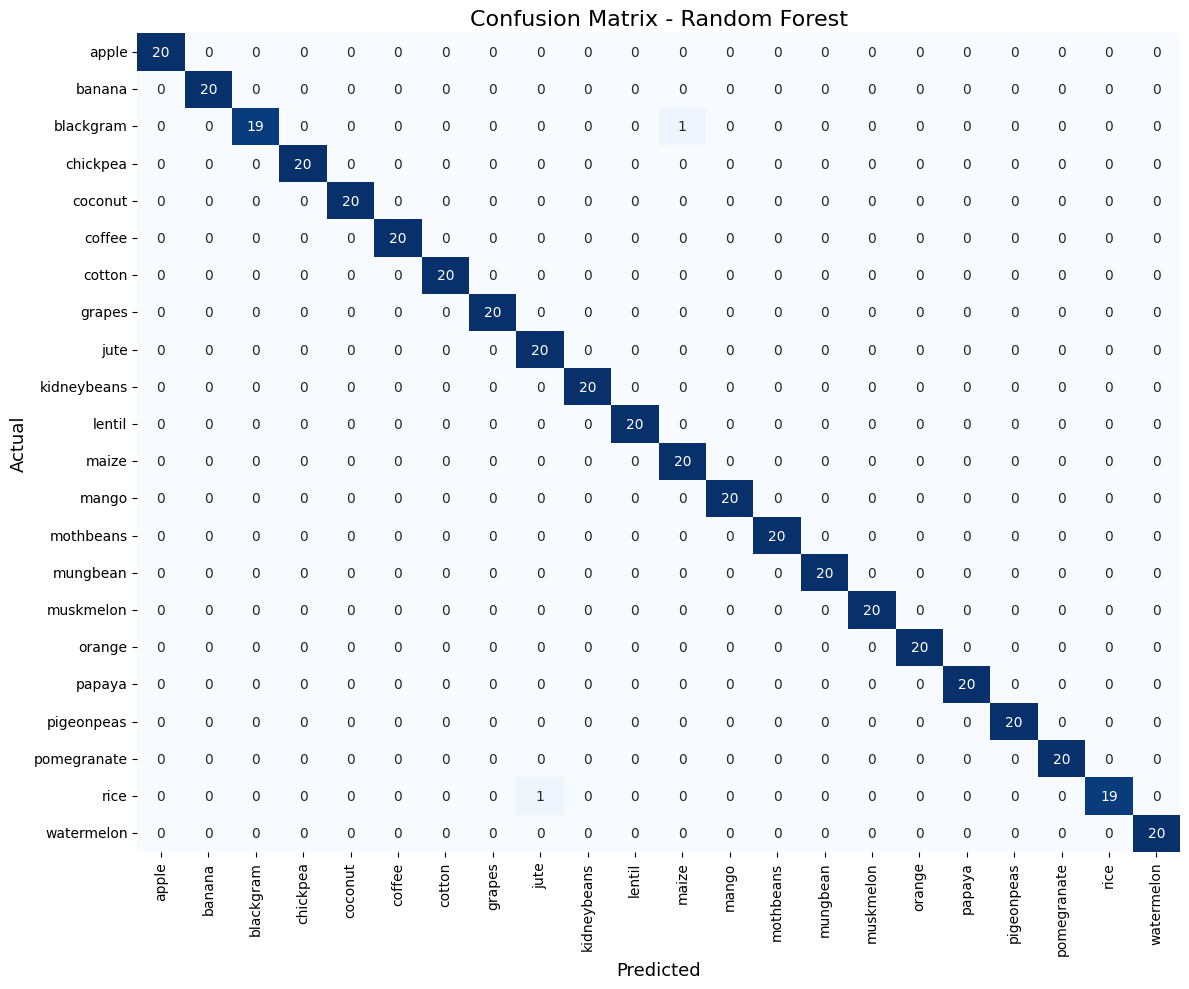

In [25]:
# Create the Random Forest model with 100 trees
forest = RandomForestClassifier(n_estimators=100, random_state=42)
# Train and evaluate it
y_pred_rf, cm_rf = evaluate_model(forest, "Random Forest")

## 5. Model comparison

In [29]:
# Turn the results dictionary into a table: one row per model
comparison = pd.DataFrame(results).T.round(4)
# Sort by test accuracy, best model first
comparison = comparison.sort_values('Test accuracy', ascending=False)
comparison

,Train accuracy,Test accuracy,Precision (macro),Recall (macro),F1-score (macro)
Random Forest,1.0000,0.9955,0.9957,0.9955,0.9955
Decision Tree,1.0000,0.9795,0.9806,0.9795,0.9794
Logistic Regression,0.9739,0.9727,0.9740,0.9727,0.9725


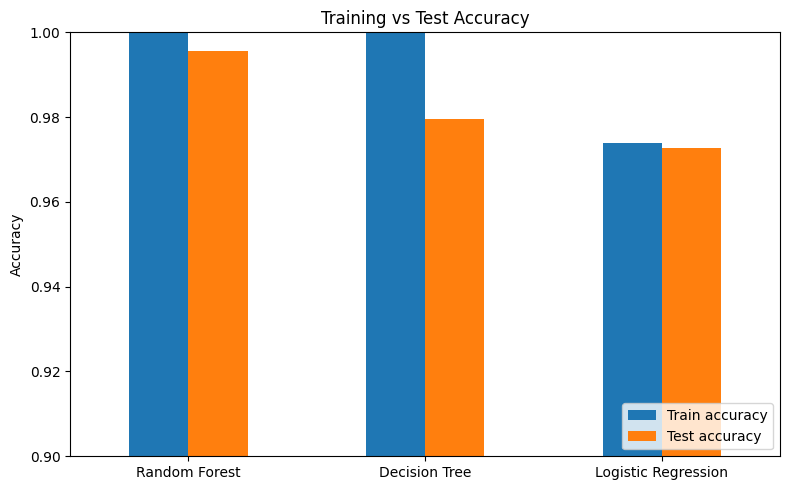

In [30]:
# Bar chart of training vs test accuracy for each model
comparison[['Train accuracy', 'Test accuracy']].plot(kind='bar', figsize=(8, 5), rot=0)
plt.title('Training vs Test Accuracy')
plt.ylabel('Accuracy')
# Zoom the y-axis in so small differences between models are visible
plt.ylim(0.9, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 5.1 Which crops get confused?
The confusion matrices are mostly diagonal, so here we list only the mistakes: for each model, which actual crop was predicted as which other crop, and how many times.

In [31]:
def list_mistakes(cm_df, name):
    """Print every (actual -> predicted) pair that the model got wrong."""
    # Copy the matrix values into a new array and set the diagonal (correct predictions) to 0
    values = cm_df.to_numpy().copy()
    np.fill_diagonal(values, 0)
    # Put the values back into a DataFrame with the crop names as row and column labels
    errors = pd.DataFrame(values, index=cm_df.index, columns=cm_df.columns)
    # stack() turns the matrix into a list of (actual, predicted, count) rows
    errors = errors.stack()
    # Keep only the pairs with at least one mistake, largest first
    errors = errors[errors > 0].sort_values(ascending=False)
    print(f"{name}: {errors.sum()} mistakes out of {len(y_test)} test samples")
    for (actual, predicted), count in errors.items():
        print(f"   actual {actual:12s} -> predicted {predicted:12s} : {count}")
    print()

# Print the mistakes of all three models
list_mistakes(cm_lr, "Logistic Regression")
list_mistakes(cm_dt, "Decision Tree")
list_mistakes(cm_rf, "Random Forest")

Logistic Regression: 12 mistakes out of 440 test samples
   actual rice         -> predicted jute         : 4
   actual lentil       -> predicted mothbeans    : 2
   actual maize        -> predicted cotton       : 1
   actual lentil       -> predicted blackgram    : 1
   actual mothbeans    -> predicted lentil       : 1
   actual mothbeans    -> predicted mango        : 1
   actual orange       -> predicted coconut      : 1
   actual papaya       -> predicted rice         : 1

Decision Tree: 9 mistakes out of 440 test samples
   actual blackgram    -> predicted lentil       : 2
   actual lentil       -> predicted mothbeans    : 2
   actual blackgram    -> predicted maize        : 1
   actual blackgram    -> predicted mothbeans    : 1
   actual jute         -> predicted rice         : 1
   actual mothbeans    -> predicted lentil       : 1
   actual rice         -> predicted jute         : 1

Random Forest: 2 mistakes out of 440 test samples
   actual blackgram    -> predicted maize     

## 6. Feature importance (proposal objective 3)
A Random Forest measures how much each feature helps the trees split the crops apart (`feature_importances_`). The values add up to 1; a higher value means the feature matters more.

rainfall       0.230
humidity       0.224
K              0.175
P              0.151
N              0.096
temperature    0.072
ph             0.051
dtype: float64


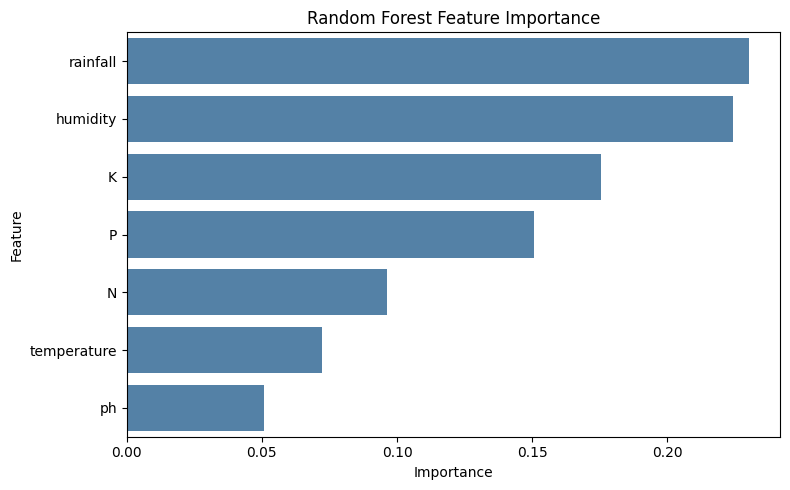

In [32]:
# Get the importance of each feature from the trained Random Forest, as a labelled Series
importances = pd.Series(forest.feature_importances_, index=X.columns)
# Sort from most to least important
importances = importances.sort_values(ascending=False)
# Print the values rounded to 3 decimals
print(importances.round(3))

# Horizontal bar chart (most important feature at the top)
plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, color='steelblue')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### 6.1 Which features matter for each crop?
The overall importance above does not say which crop depends on which feature. To see this, we look at each crop's average **standardized** value for every feature (computed on the training set).
Because the values are z-scores, +2 means "2 standard deviations above the average farm", so very high or very low values show what makes that crop special (e.g. rice needs much more rainfall than average).

/tmp/ipykernel_368/1941051654.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  crop_profiles = train_scaled_with_label.groupby('label').mean()


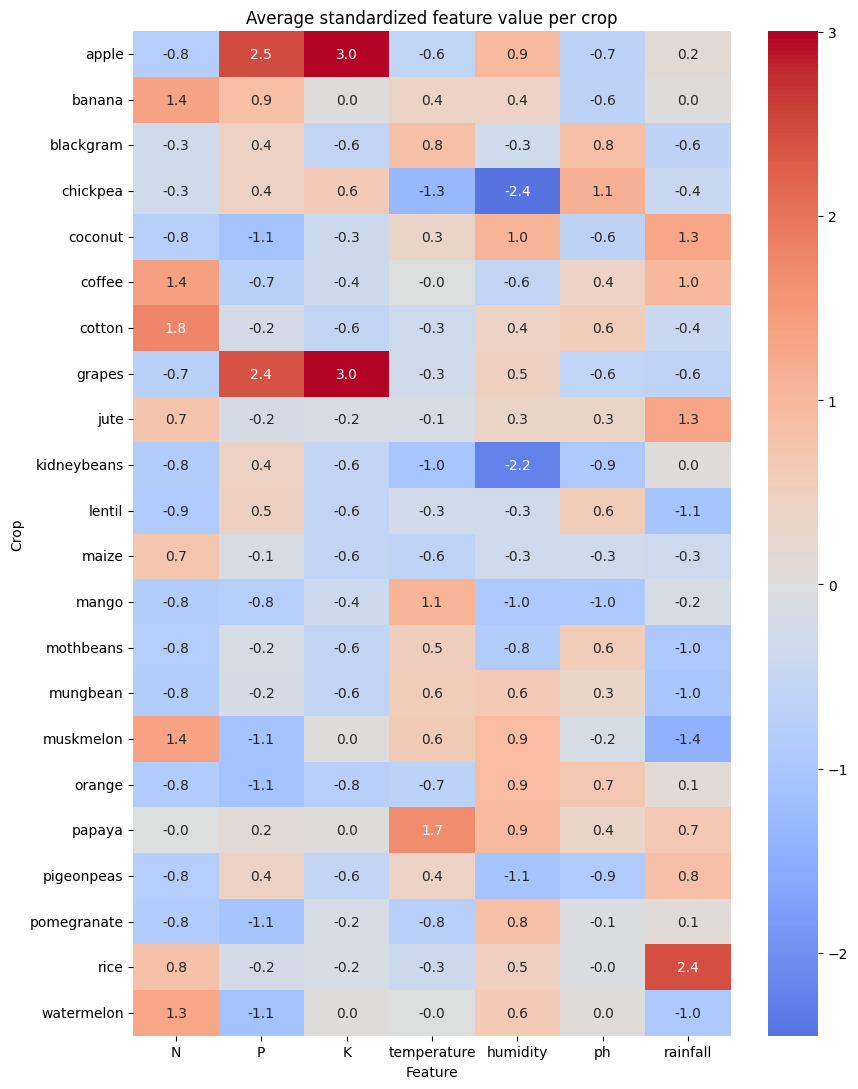

Most distinctive feature for each crop:
   apple       : high K (z = +3.00)
   banana      : high N (z = +1.35)
   blackgram   : high ph (z = +0.84)
   chickpea    : low humidity (z = -2.45)
   coconut     : high rainfall (z = +1.29)
   coffee      : high N (z = +1.39)
   cotton      : high N (z = +1.80)
   grapes      : high K (z = +3.00)
   jute        : high rainfall (z = +1.32)
   kidneybeans : low humidity (z = -2.23)
   lentil      : low rainfall (z = -1.06)
   maize       : high N (z = +0.72)
   mango       : high temperature (z = +1.08)
   mothbeans   : low rainfall (z = -0.95)
   mungbean    : low rainfall (z = -0.99)
   muskmelon   : low rainfall (z = -1.43)
   orange      : low P (z = -1.11)
   papaya      : high temperature (z = +1.67)
   pigeonpeas  : low humidity (z = -1.06)
   pomegranate : low P (z = -1.06)
   rice        : high rainfall (z = +2.43)
   watermelon  : high N (z = +1.32)


In [33]:
# Combine the scaled training features with their crop labels
train_scaled_with_label = X_train_scaled.copy()
train_scaled_with_label['label'] = y_train
# Average z-score of each feature for each crop (rows = crops, columns = features)
crop_profiles = train_scaled_with_label.groupby('label').mean()

# Heatmap: red = above average, blue = below average
plt.figure(figsize=(9, 11))
sns.heatmap(crop_profiles, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Average standardized feature value per crop')
plt.xlabel('Feature')
plt.ylabel('Crop')
plt.tight_layout()
plt.show()

# For each crop, print the feature that is furthest from the average (largest absolute z-score)
print("Most distinctive feature for each crop:")
for crop, row in crop_profiles.iterrows():
    feature = row.abs().idxmax()      # name of the feature with the largest |z|
    value = row[feature]              # its signed value (+ above average, - below)
    direction = "high" if value > 0 else "low"
    print(f"   {crop:12s}: {direction} {feature} (z = {value:+.2f})")